In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint



In [113]:
G=100

M=40
R=1
m=10
δ=100

k=G*M

def V(x,y):
    r=np.sqrt(x**2+y**2)

    return -k*m/r

def KE(vx,vy):

    v=np.sqrt(vx**2+vy**2)

    return 0.5*m*(v**2)

def U(sol):
    return KE(sol.T[2],sol.T[3])+V(sol.T[0],sol.T[1])


def acc(state , t):
    x,y,vx,vy=state

    r=np.sqrt(x**2+y**2)
    θ=np.arctan2(y,x)

    a=-(k/r**2)-(δ/r**3)


    if r>R :
        ax=a*np.cos(θ)
        ay=a*np.sin(θ)
        return (vx,vy,ax,ay)
    else:
        ax=0
        ay=0
        return (vx,vy,ax,ay)

    

t=np.linspace(0,50**4,1000000)

state0=(10,8,10,-20)

sol=odeint(acc,state0,t=t,rtol=1e-9, atol=1e-9)

KeyboardInterrupt: 

(-627.3404443939983, -622.091346670592)

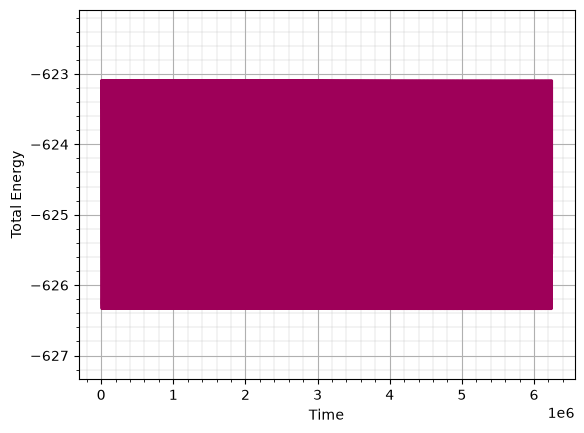

In [114]:
plt.plot(t,U(sol),color="#9e0059",lw=1.5)
plt.grid(True)
plt.minorticks_on()
plt.grid(which="minor",lw=0.2)
plt.xlabel("Time")
plt.ylabel("Total Energy")
plt.ylim(np.min(U(sol))-1,np.max(U(sol))+1)

(-100.0, 100.0)

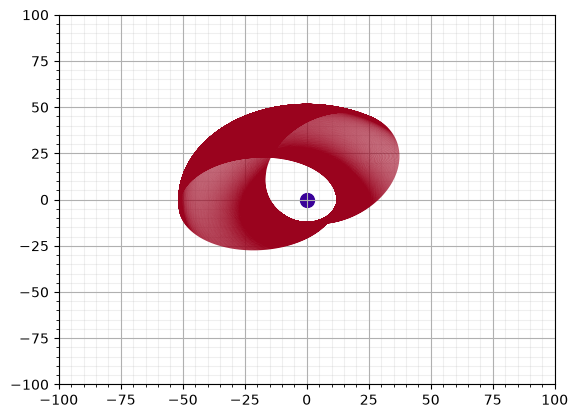

In [115]:
plt.plot(sol.T[0],sol.T[1],color="#9a031e",lw=0.1)
plt.grid(True)
plt.minorticks_on()
plt.grid(which="minor",alpha=0.2)
plt.scatter(0,0,s=100,color="#390099")

plt.xlim(-100,100)
plt.ylim(-100,100)

